<h1>Train — ResNet-50</h1>

Trains and evaluates ResNet-50 using the tuned hyperparameters from `ARCH_HYPERPARAMS["resnet50"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: off
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']
Train: 1348 | Val: 323 | Test: 856


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["resnet50"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-50: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders — its own (capped) batch size, and
# (for InceptionNet v3) its own image size.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-50: micro batch = 16, accumulation steps = 1 (effective batch size ≈ 16, tuned value = 16)


## Define the model

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with ResNet-50)
# ---------------------------------------------------------
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the Bayesian-optimized step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ResNet-50] Epoch   1/100 | LR: 1.33e-04 | train loss 0.8456 acc 0.636 | val loss 0.6173 acc 0.718 *


[ResNet-50] Epoch   2/100 | LR: 1.33e-04 | train loss 0.4570 acc 0.784 | val loss 0.6107 acc 0.783 *


[ResNet-50] Epoch   3/100 | LR: 1.33e-04 | train loss 0.2723 acc 0.868 | val loss 0.8646 acc 0.672


[ResNet-50] Epoch   4/100 | LR: 1.33e-04 | train loss 0.2049 acc 0.915 | val loss 0.6514 acc 0.783


[ResNet-50] Epoch   5/100 | LR: 1.33e-04 | train loss 0.1030 acc 0.945 | val loss 0.8077 acc 0.755


...

[ResNet-50] Epoch   8/100 | LR: 1.33e-04 | train loss 0.1177 acc 0.958 | val loss 0.6328 acc 0.771


[ResNet-50] Epoch   9/100 | LR: 1.33e-04 | train loss 0.0710 acc 0.964 | val loss 0.7765 acc 0.802


[ResNet-50] Epoch  10/100 | LR: 1.33e-04 | train loss 0.0471 acc 0.981 | val loss 0.8163 acc 0.783


[ResNet-50] Epoch  11/100 | LR: 1.33e-04 | train loss 0.0228 acc 0.989 | val loss 0.8638 acc 0.820


[ResNet-50] Epoch  12/100 | LR: 1.33e-04 | train loss 0.0690 acc 0.971 | val loss 0.7058 acc 0.789

[ResNet-50] No val loss improvement for 10 epochs — stopping early at epoch 12.

[ResNet-50] Restored best checkpoint (val loss = 0.6107)


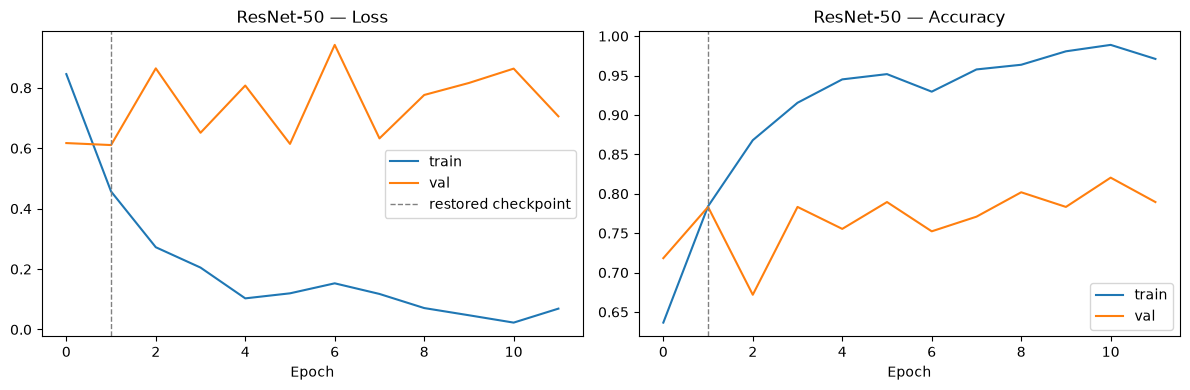

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-50", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-50")

## Evaluate on the test set

[ResNet-50] Test accuracy: 0.687


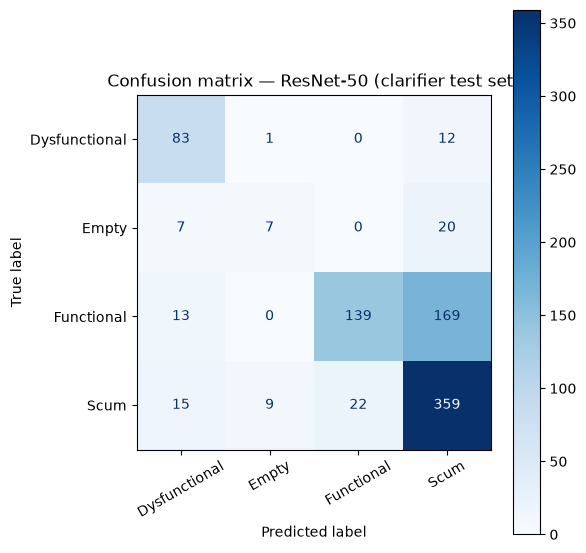

               precision    recall  f1-score   support

Dysfunctional      0.703     0.865     0.776        96
        Empty      0.412     0.206     0.275        34
   Functional      0.863     0.433     0.577       321
         Scum      0.641     0.886     0.744       405

     accuracy                          0.687       856
    macro avg      0.655     0.597     0.593       856
 weighted avg      0.722     0.687     0.666       856



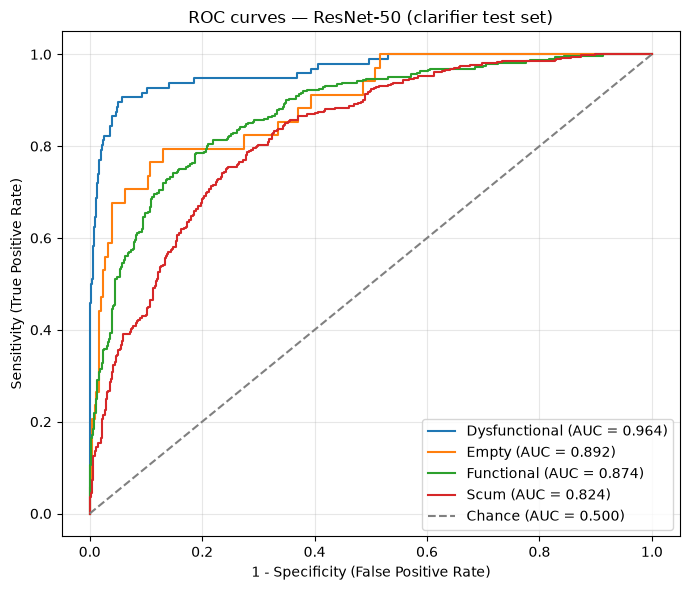

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.964
  Empty          : 0.892
  Functional     : 0.874
  Scum           : 0.824

Mean AUC (over 4/4 classes with test examples): 0.888


(np.float64(0.6869158878504673),
 {'Dysfunctional': 0.9639939692982455,
  'Empty': 0.8921926434807499,
  'Functional': 0.8735027804466183,
  'Scum': 0.8242095754290876})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-50", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

In [6]:
save_result("ResNet-50", "resnet50")

Saved results to ../results/clarifier_noaug/results_clarifier_resnet50_chronological.pkl
Saved model weights to ../models/pad/clarifier_resnet50_cnn.pt
